<a href="https://colab.research.google.com/github/palashDoshi1/CMPSC-448-Midterm-Project/blob/main/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## RQ1: CNN — Output-Only LLM Attribution

### Research Question

Can a CNN identify whether a response was generated by GPT, Claude, or Gemini using only the generated output text?

### Experimental Setup

The classifier uses the `output` column as input and the `model` column as its target. The predefined dataset contains 378 training, 81 validation, and 81 test responses.

Text is encoded using the shared `data/vocab.json` and tokenizer `r"\w+|[^\w\s]"`. Sequences are truncated or padded on the right to 512 tokens. The class mapping is GPT=0, Claude=1, and Gemini=2.

### Model Architecture and Training

The CNN uses trainable 128-dimensional embeddings, convolutional filters spanning 3, 5, and 7 tokens, padding-aware pooling, dropout of 0.3, and a three-class output layer.

Training uses Adam with a learning rate of 0.001, a batch size of 16, and a maximum of 20 epochs. Checkpoint selection is based on the lowest validation loss, with early-stopping patience of four epochs.

### Results

| Metric | CNN result |
|---|---:|
| Selected checkpoint | Epoch 9 |
| Best validation loss | 0.4046 |
| Validation accuracy at selected epoch | 86.42% |
| Training stopped | Epoch 13 |
| Test accuracy | 82.72% |
| Test macro-F1 | 0.8293 |
| Correct test predictions | 67/81 |

### Comparison and Interpretation

Sid’s output-only LSTM achieved 71.60% test accuracy and 0.7141 test macro-F1. The CNN classified nine more responses correctly, achieving approximately 11.11 percentage points higher accuracy and 0.1152 higher macro-F1.

These results favor the CNN for output-only attribution in the evaluated runs. They do not establish that the CNN will outperform the LSTM across other datasets or random seeds.

The notebook review reported matching data paths and preprocessing settings. Identical data contents remain conditional on the shared GitHub files being unchanged between runs.

The CNN’s RQ1 test results will serve as the output-only baseline for RQ2.


In [1]:
# Step 1: Import libraries and check GPU

import torch
import pandas as pd
import numpy as np
import random
import re

from collections import Counter

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

PyTorch version: 2.11.0+cu130
GPU available: True
Device: cuda


In [2]:
# Step 2: Load datasets from GitHub

BASE = "https://raw.githubusercontent.com/palashDoshi1/CMPSC-448-Midterm-Project/main/data/"

train_df = pd.read_csv(BASE + "train.csv")
val_df = pd.read_csv(BASE + "validation.csv")
test_df = pd.read_csv(BASE + "test.csv")

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

print("\nDataset columns:", train_df.columns.tolist())

print("\nTraining label distribution:")
print(train_df["model"].value_counts())

Training: (378, 5)
Validation: (81, 5)
Testing: (81, 5)

Dataset columns: ['prompt_id', 'category', 'model', 'input', 'output']

Training label distribution:
model
gpt       126
claude    126
gemini    126
Name: count, dtype: int64


In [3]:
# Step 3: Validate datasets and prevent data leakage

required = {"prompt_id", "category", "model", "input", "output"}

LABEL_MAP = {
    "gpt": 0,
    "claude": 1,
    "gemini": 2
}

# Verify required columns
for frame in [train_df, val_df, test_df]:
    assert required.issubset(frame.columns)

# Verify expected dataset sizes
assert len(train_df) == 378
assert len(val_df) == 81
assert len(test_df) == 81

# Verify no prompt overlap
train_ids = set(train_df["prompt_id"])
val_ids = set(val_df["prompt_id"])
test_ids = set(test_df["prompt_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

# Verify labels, missing values, and duplicates
for frame in [train_df, val_df, test_df]:

    assert set(frame["model"].unique()) == set(LABEL_MAP)

    assert not frame[list(required)].isnull().any().any()

    assert not frame.duplicated(
        subset=["prompt_id", "model"]
    ).any()

    # Each prompt should have responses from all 3 LLMs
    assert frame.groupby("prompt_id")["model"].nunique().eq(3).all()

print("All validation checks passed!")
print("No prompt overlap between train, validation, and test.")
print("Ready for preprocessing and CNN training!")

All validation checks passed!
No prompt overlap between train, validation, and test.
Ready for preprocessing and CNN training!


In [4]:
# Step 4: Shared training configuration

SEED = 42

MAX_VOCAB_SIZE = 10000
MAX_SEQUENCE_LENGTH = 512

EMBEDDING_DIM = 128
BATCH_SIZE = 16
LEARNING_RATE = 0.001
DROPOUT = 0.3

MAX_EPOCHS = 20
PATIENCE = 4

# Set random seeds for reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)
print("Maximum vocabulary:", MAX_VOCAB_SIZE)
print("Maximum sequence length:", MAX_SEQUENCE_LENGTH)
print("Embedding dimension:", EMBEDDING_DIM)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Device:", device)

Random seed: 42
Maximum vocabulary: 10000
Maximum sequence length: 512
Embedding dimension: 128
Batch size: 16
Learning rate: 0.001
Device: cuda


In [5]:
# Step 5: Load shared vocabulary from GitHub

import json
from urllib.request import urlopen

VOCAB_URL = BASE + "vocab.json"

with urlopen(VOCAB_URL) as response:
    vocab = json.load(response)

# Validate shared vocabulary
assert len(vocab) == MAX_VOCAB_SIZE
assert vocab["<PAD>"] == 0
assert vocab["<UNK>"] == 1

assert set(vocab.values()) == set(range(len(vocab)))

print("Shared vocabulary loaded successfully!")
print("Vocabulary size:", len(vocab))
print("PAD token:", vocab["<PAD>"])
print("UNK token:", vocab["<UNK>"])

print("\nFirst 20 vocabulary entries:")
for token, idx in list(vocab.items())[:20]:
    print(f"{idx}: {token}")

Shared vocabulary loaded successfully!
Vocabulary size: 10000
PAD token: 0
UNK token: 1

First 20 vocabulary entries:
0: <PAD>
1: <UNK>
2: ,
3: .
4: *
5: -
6: and
7: the
8: a
9: to
10: :
11: )
12: (
13: |
14: of
15: is
16: #
17: in
18: ─
19: or


In [6]:
# Step 6: Tokenize and encode text into numerical sequences

def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", str(text))


def encode_text(text):
    tokens = tokenize(text)

    # Convert tokens to vocabulary IDs
    encoded = [
        vocab.get(token, vocab["<UNK>"])
        for token in tokens
    ]

    # Truncate long sequences
    encoded = encoded[:MAX_SEQUENCE_LENGTH]

    # Pad short sequences
    if len(encoded) < MAX_SEQUENCE_LENGTH:
        encoded += [vocab["<PAD>"]] * (
            MAX_SEQUENCE_LENGTH - len(encoded)
        )

    return encoded


# Encode output text for RQ1
X_train = [encode_text(text) for text in train_df["output"]]
X_val = [encode_text(text) for text in val_df["output"]]
X_test = [encode_text(text) for text in test_df["output"]]


# Convert model names into numerical labels
y_train = train_df["model"].map(LABEL_MAP).tolist()
y_val = val_df["model"].map(LABEL_MAP).tolist()
y_test = test_df["model"].map(LABEL_MAP).tolist()


# Convert everything into PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.long)
X_val = torch.tensor(X_val, dtype=torch.long)
X_test = torch.tensor(X_test, dtype=torch.long)

y_train = torch.tensor(y_train, dtype=torch.long)
y_val = torch.tensor(y_val, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)


print("Training X:", X_train.shape)
print("Validation X:", X_val.shape)
print("Testing X:", X_test.shape)

print("\nTraining labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)

print("\nFirst 20 token IDs:")
print(X_train[0][:20])

Training X: torch.Size([378, 512])
Validation X: torch.Size([81, 512])
Testing X: torch.Size([81, 512])

Training labels: torch.Size([378])
Validation labels: torch.Size([81])
Testing labels: torch.Size([81])

First 20 token IDs:
tensor([  16,   16,  191,  113,  789,  118,  540,   22,  284,  453,   17, 2194,
          28,  525,   58,  582,   37,  226,  127, 2649])


In [7]:
# Step 7: Create PyTorch datasets and DataLoaders

from torch.utils.data import TensorDataset, DataLoader


# Create datasets
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)


# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


# Verify batch dimensions
sample_X, sample_y = next(iter(train_loader))

print("\nSample batch X shape:", sample_X.shape)
print("Sample batch y shape:", sample_y.shape)

print("\nDataLoaders created successfully!")

Training batches: 24
Validation batches: 6
Testing batches: 6

Sample batch X shape: torch.Size([16, 512])
Sample batch y shape: torch.Size([16])

DataLoaders created successfully!


In [8]:
# Cell 8: CNN architecture

import torch
import torch.nn as nn

PAD_IDX = vocab["<PAD>"]
NUM_CLASSES = len(LABEL_MAP)

assert sorted(LABEL_MAP.values()) == list(range(NUM_CLASSES)), (
    "LABEL_MAP must map class names to IDs 0, 1, ..., NUM_CLASSES - 1."
)
assert set(vocab.values()) == set(range(len(vocab))), (
    "Vocabulary IDs must be consecutive, starting at 0."
)

class TextCNN(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        num_classes,
        pad_idx,
        dropout,
        num_filters=128,
        kernel_sizes=(3, 5, 7),
    ):
        super().__init__()
        self.pad_idx = pad_idx

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=pad_idx,
        )

        self.convs = nn.ModuleList([
            nn.Conv1d(
                in_channels=embedding_dim,
                out_channels=num_filters,
                kernel_size=k,
                padding=k // 2,
            )
            for k in kernel_sizes
        ])

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(
            num_filters * len(kernel_sizes),
            num_classes,
        )

    def forward(self, x):
        # x: [batch_size, sequence_length]
        token_mask = x.ne(self.pad_idx)
        has_tokens = token_mask.any(dim=1, keepdim=True)

        # Conv1d expects [batch_size, embedding_dim, sequence_length].
        embedded = self.embedding(x).transpose(1, 2)

        pooled_features = []
        for conv in self.convs:
            features = torch.relu(conv(embedded))

            # Exclude padding positions from global max pooling.
            features = features.masked_fill(
                ~token_mask.unsqueeze(1),
                float("-inf"),
            )
            pooled = features.amax(dim=2)

            # An all-padding response gets zero features.
            pooled = torch.where(
                has_tokens,
                pooled,
                torch.zeros_like(pooled),
            )
            pooled_features.append(pooled)

        combined = torch.cat(pooled_features, dim=1)

        # Return raw logits; CrossEntropyLoss handles normalization.
        return self.classifier(self.dropout(combined))


model = TextCNN(
    vocab_size=len(vocab),
    embedding_dim=EMBEDDING_DIM,
    num_classes=NUM_CLASSES,
    pad_idx=PAD_IDX,
    dropout=DROPOUT,
).to(device)

# Check output shape without consuming the shuffled training loader.
with torch.no_grad():
    example_x = torch.tensor(
        [[vocab["<UNK>"], PAD_IDX, PAD_IDX]],
        dtype=torch.long,
        device=device,
    )
    example_logits = model(example_x)

assert example_logits.shape == (1, NUM_CLASSES)

print(model)
print("\nDevice:", device)
print("Output shape:", tuple(example_logits.shape))
print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}",
)

TextCNN(
  (embedding): Embedding(10000, 128, padding_idx=0)
  (convs): ModuleList(
    (0): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): Conv1d(128, 128, kernel_size=(5,), stride=(1,), padding=(2,))
    (2): Conv1d(128, 128, kernel_size=(7,), stride=(1,), padding=(3,))
  )
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=384, out_features=3, bias=True)
)

Device: cuda
Output shape: (1, 3)
Trainable parameters: 1,527,299


In [9]:
# Cell 9: Train with validation and early stopping

from pathlib import Path
import numpy as np
from sklearn.metrics import f1_score

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
)

CHECKPOINT_PATH = Path("/content/best_cnn.pt")
CHECKPOINT_PATH.parent.mkdir(parents=True, exist_ok=True)

class_ids = list(range(NUM_CLASSES))


def run_epoch(loader, training=False):
    model.train(training)

    total_loss = 0.0
    total_examples = 0
    true_labels = []
    predicted_labels = []

    with torch.set_grad_enabled(training):
        for X, y in loader:
            X = X.to(device, dtype=torch.long)
            y = y.to(device, dtype=torch.long)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(X)
            loss = criterion(logits, y)

            if not torch.isfinite(loss).item():
                raise RuntimeError("Non-finite loss detected.")

            if training:
                loss.backward()
                optimizer.step()

            batch_size = y.size(0)
            total_loss += loss.item() * batch_size
            total_examples += batch_size

            true_labels.extend(y.detach().cpu().tolist())
            predicted_labels.extend(
                logits.argmax(dim=1).detach().cpu().tolist()
            )

    if total_examples == 0:
        raise ValueError("The DataLoader contains no examples.")

    accuracy = float(
        np.mean(np.array(true_labels) == np.array(predicted_labels))
    )
    macro_f1 = f1_score(
        true_labels,
        predicted_labels,
        labels=class_ids,
        average="macro",
        zero_division=0,
    )

    return total_loss / total_examples, accuracy, macro_f1


history = []
best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss, train_acc, train_f1 = run_epoch(
        train_loader, training=True
    )
    val_loss, val_acc, val_f1 = run_epoch(
        val_loader, training=False
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
    })

    improved = val_loss < best_val_loss

    if improved:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        # CPU copies make the saved weights portable across devices.
        torch.save({
            "model_state_dict": {
                name: tensor.detach().cpu().clone()
                for name, tensor in model.state_dict().items()
            },
            "epoch": epoch,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "val_macro_f1": val_f1,
            "label_map": dict(LABEL_MAP),
            "vocab": dict(vocab),
            "model_config": {
                "vocab_size": len(vocab),
                "embedding_dim": EMBEDDING_DIM,
                "num_classes": NUM_CLASSES,
                "pad_idx": PAD_IDX,
                "dropout": DROPOUT,
                "num_filters": 128,
                "kernel_sizes": (3, 5, 7),
            },
        }, CHECKPOINT_PATH)
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train loss: {train_loss:.4f}, acc: {train_acc:.2%} | "
        f"Val loss: {val_loss:.4f}, acc: {val_acc:.2%}, "
        f"macro-F1: {val_f1:.4f}"
        + (" | Saved best model" if improved else "")
    )

    if epochs_without_improvement >= PATIENCE:
        print(
            f"\nEarly stopping: validation loss did not improve "
            f"for {PATIENCE} consecutive epochs."
        )
        break

# Restore the best validation checkpoint, not the final epoch.
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True,
)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print(f"\nBest epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Checkpoint saved to: {CHECKPOINT_PATH}")

Epoch 01/20 | Train loss: 1.1636, acc: 38.62% | Val loss: 0.9683, acc: 51.85%, macro-F1: 0.4125 | Saved best model
Epoch 02/20 | Train loss: 0.4854, acc: 82.80% | Val loss: 0.6628, acc: 75.31%, macro-F1: 0.7492 | Saved best model
Epoch 03/20 | Train loss: 0.2804, acc: 93.12% | Val loss: 0.6284, acc: 72.84%, macro-F1: 0.7107 | Saved best model
Epoch 04/20 | Train loss: 0.1781, acc: 96.83% | Val loss: 0.5232, acc: 83.95%, macro-F1: 0.8389 | Saved best model
Epoch 05/20 | Train loss: 0.1049, acc: 98.68% | Val loss: 0.5324, acc: 79.01%, macro-F1: 0.7811
Epoch 06/20 | Train loss: 0.0727, acc: 100.00% | Val loss: 0.5238, acc: 80.25%, macro-F1: 0.7935
Epoch 07/20 | Train loss: 0.0685, acc: 98.68% | Val loss: 0.5929, acc: 74.07%, macro-F1: 0.7335
Epoch 08/20 | Train loss: 0.0352, acc: 99.74% | Val loss: 0.4712, acc: 83.95%, macro-F1: 0.8384 | Saved best model
Epoch 09/20 | Train loss: 0.0321, acc: 99.74% | Val loss: 0.4046, acc: 86.42%, macro-F1: 0.8642 | Saved best model
Epoch 10/20 | Train l

Selected checkpoint: epoch 9
Test examples: 81
Test accuracy: 82.72%
Test macro-F1: 0.8293

Classification report:
              precision    recall  f1-score   support

         gpt     0.7419    0.8519    0.7931        27
      claude     0.9565    0.8148    0.8800        27
      gemini     0.8148    0.8148    0.8148        27

    accuracy                         0.8272        81
   macro avg     0.8378    0.8272    0.8293        81
weighted avg     0.8378    0.8272    0.8293        81



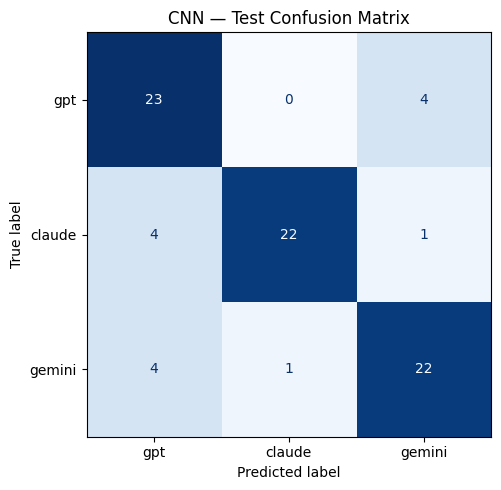

In [10]:
# Cell 10: Final test evaluation

import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True,
)

assert checkpoint["label_map"] == dict(LABEL_MAP), (
    "LABEL_MAP differs from the saved checkpoint."
)
assert checkpoint["vocab"] == dict(vocab), (
    "Vocabulary differs from the saved checkpoint."
)

model = TextCNN(**checkpoint["model_config"]).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

y_true = []
y_pred = []

with torch.inference_mode():
    for X, y in test_loader:
        X = X.to(device, dtype=torch.long)

        logits = model(X)
        predictions = logits.argmax(dim=1)

        y_true.extend(y.detach().cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

if not y_true:
    raise ValueError("The test DataLoader contains no examples.")

class_ids = list(range(NUM_CLASSES))
id_to_label = {idx: str(name) for name, idx in LABEL_MAP.items()}
class_names = [id_to_label[idx] for idx in class_ids]

test_accuracy = accuracy_score(y_true, y_pred)
test_macro_f1 = f1_score(
    y_true,
    y_pred,
    labels=class_ids,
    average="macro",
    zero_division=0,
)

print(f"Selected checkpoint: epoch {checkpoint['epoch']}")
print(f"Test examples: {len(y_true)}")
print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Test macro-F1: {test_macro_f1:.4f}")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=class_ids,
    target_names=class_names,
    digits=4,
    zero_division=0,
))

cm = confusion_matrix(y_true, y_pred, labels=class_ids)

fig, ax = plt.subplots(figsize=(7, 5))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names,
)
display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False,
)
ax.set_title("CNN — Test Confusion Matrix")
plt.tight_layout()
plt.show()

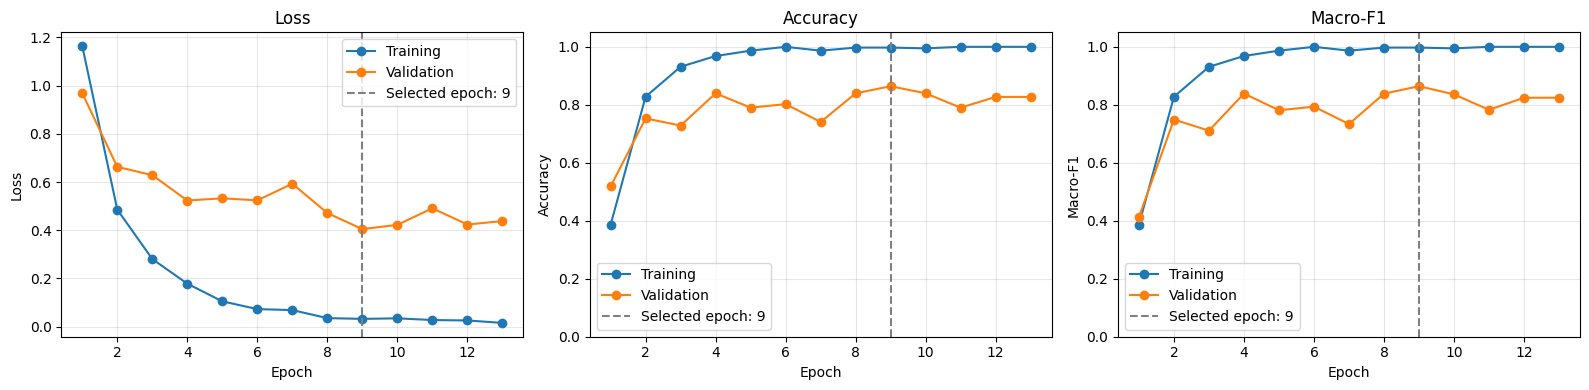

In [11]:
# Cell 11: Plot training and validation curves

import pandas as pd
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)
selected_epoch = int(checkpoint["epoch"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

plots = [
    ("train_loss", "val_loss", "Loss"),
    ("train_accuracy", "val_accuracy", "Accuracy"),
    ("train_macro_f1", "val_macro_f1", "Macro-F1"),
]

for ax, (train_key, val_key, title) in zip(axes, plots):
    ax.plot(
        history_df["epoch"], history_df[train_key],
        marker="o", label="Training"
    )
    ax.plot(
        history_df["epoch"], history_df[val_key],
        marker="o", label="Validation"
    )
    ax.axvline(
        selected_epoch, color="gray", linestyle="--",
        label=f"Selected epoch: {selected_epoch}"
    )
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()

    if title != "Loss":
        ax.set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig("/content/cnn_training_curves.png", dpi=200)
plt.show()

In [12]:
# Cell 12: Save RQ1 results permanently to Google Drive

from google.colab import drive
from pathlib import Path
from datetime import datetime
import json
import shutil
import pandas as pd
from sklearn.metrics import classification_report

drive.mount("/content/drive")

# Separate folder for each export
export_dir = (
    Path("/content/drive/MyDrive/CMPSC448/CNN_RQ1")
    / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
export_dir.mkdir(parents=True, exist_ok=False)

# Save training history
pd.DataFrame(history).to_csv(
    export_dir / "cnn_rq1_history.csv", index=False
)

# Save metrics from the selected RQ1 checkpoint and test evaluation
metrics = {
    "model": "CNN",
    "experiment": "RQ1_output_only",
    "checkpoint_selection": "lowest_validation_loss",
    "best_epoch": int(checkpoint["epoch"]),
    "selected_validation_loss": float(checkpoint["val_loss"]),
    "selected_validation_accuracy": float(checkpoint["val_accuracy"]),
    "selected_validation_macro_f1": float(checkpoint["val_macro_f1"]),
    "last_training_epoch": int(history[-1]["epoch"]),
    "test_accuracy": float(test_accuracy),
    "test_macro_f1": float(test_macro_f1),
    "test_samples": len(y_true),
    "correct_predictions": sum(
        actual == predicted for actual, predicted in zip(y_true, y_pred)
    ),
    "label_map": dict(LABEL_MAP),
    "confusion_matrix_label_order": class_names,
    "confusion_matrix": cm.tolist(),
    "vocab_size": len(vocab),
    "max_sequence_length": MAX_SEQUENCE_LENGTH,
    "seed": SEED,
    "classification_report": classification_report(
        y_true,
        y_pred,
        labels=class_ids,
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    ),
}

with open(export_dir / "cnn_rq1_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

# Preserve the selected model checkpoint
shutil.copy2(CHECKPOINT_PATH, export_dir / "cnn_rq1_best.pt")

# Save the vocabulary and exact loaded dataset contents
with open(export_dir / "cnn_rq1_vocab.json", "w") as f:
    json.dump(vocab, f, ensure_ascii=False, indent=2)

for name, frame in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    frame.to_csv(export_dir / f"{name}.csv", index=False)

# Save individual test predictions
predictions = test_df[["prompt_id", "model"]].reset_index(drop=True).copy()
predictions["true_label_id"] = y_true
predictions["predicted_label_id"] = y_pred
predictions["predicted_model"] = [id_to_label[p] for p in y_pred]
predictions.to_csv(export_dir / "cnn_rq1_predictions.csv", index=False)

# Preserve the training plot if available
plot_path = Path("/content/cnn_training_curves.png")
if plot_path.exists():
    shutil.copy2(plot_path, export_dir / plot_path.name)

print("RQ1 results saved to:", export_dir)
print("\nSaved files:")
for file in sorted(export_dir.iterdir()):
    print(file.name)

Mounted at /content/drive
RQ1 results saved to: /content/drive/MyDrive/CMPSC448/CNN_RQ1/20261011_175039_065550

Saved files:
cnn_rq1_best.pt
cnn_rq1_history.csv
cnn_rq1_metrics.json
cnn_rq1_predictions.csv
cnn_rq1_vocab.json
cnn_training_curves.png
test.csv
train.csv
validation.csv


## RQ2: Input-Only vs. Output-Only vs. Combined Input/Output

### Research Question

Does using the original prompt, the generated response, or both improve the ability of a CNN to identify which LLM produced a response?

### Experimental Setup

We compare three input configurations:

- **Input-only:** The original prompt (`input`).
- **Output-only:** The generated response (`output`), using the completed RQ1 CNN results.
- **Combined:** The original prompt and generated response separated by a special `[SEP]` token.

All experiments use the existing training, validation, and test splits. The CNN architecture and label mapping remain consistent with RQ1: GPT=0, Claude=1, and Gemini=2.

To match Sid’s RQ2 setup, separate vocabularies will be constructed for the input-only and combined configurations using only their training text. Each configuration’s vocabulary and encoding rules will be shared between the CNN and LSTM.

The maximum encoded sequence length remains 512 tokens. For combined inputs, both notebooks will use the same allocation of prompt and response tokens and reserve one position for `[SEP]`.

### Model Training

Two fresh CNN models will be trained: one using prompts only and another using prompts and responses together. The completed RQ1 output-only model will serve as the baseline.

The new models will use Adam with a learning rate of 0.001, a batch size of 16, dropout of 0.3, and a maximum of 20 epochs. To match the RQ2 LSTM experiments, early stopping will use a patience of four epochs, with checkpoints selected by the highest validation macro-F1.

Each experiment’s checkpoint, training history, vocabulary, and evaluation results will be saved separately.

### Evaluation

After restoring each selected checkpoint, we will evaluate it on the held-out test split and report accuracy, macro-F1, per-class precision and recall, and a confusion matrix.

The existing output-only CNN baseline achieved 82.72% test accuracy and 0.8293 test macro-F1.

The input-only experiment serves as a control. Because each prompt is shared by all three model classes, identical prompt text alone cannot distinguish the generating model. With balanced classes and deterministic predictions, its expected accuracy is 33.33%.

### Interpretation

We will compare the three configurations to determine whether prompt context improves attribution over response text alone. Combined inputs may provide useful context, but reserving space for prompts also reduces the response text available within the 512-token limit.

The input-only and combined results will be added after training and test evaluation are complete.

In [13]:
# RQ2 — Load Sid's shared vocabularies

import json
from urllib.request import urlopen

RQ2_BASE = (
    "https://raw.githubusercontent.com/"
    "palashDoshi1/CMPSC-448-Midterm-Project/"
    f"main/data/"
)

def load_rq2_vocab(filename):
    with urlopen(RQ2_BASE + filename) as response:
        loaded_vocab = json.load(response)

    assert loaded_vocab["<PAD>"] == 0
    assert loaded_vocab["<UNK>"] == 1
    assert set(loaded_vocab.values()) == set(range(len(loaded_vocab)))
    return loaded_vocab

rq2_input_vocab = load_rq2_vocab("vocab_input.json")
rq2_combined_vocab = load_rq2_vocab("vocab_combined.json")

assert rq2_combined_vocab["[SEP]"] == 2

print("Input vocabulary:", len(rq2_input_vocab))
print("Combined vocabulary:", len(rq2_combined_vocab))
print("Combined separator ID:", rq2_combined_vocab["[SEP]"])

Input vocabulary: 1782
Combined vocabulary: 10000
Combined separator ID: 2


In [14]:
# RQ2 — Encode input-only and combined text

import torch

RQ2_SEQUENCE_LENGTH = 512
RQ2_PROMPT_LIMIT = 128
RQ2_RESPONSE_LIMIT = 383

def rq2_token_ids(text, vocabulary):
    return [
        vocabulary.get(token, vocabulary["<UNK>"])
        for token in tokenize(text)
    ]

def rq2_pad(ids, vocabulary):
    assert len(ids) <= RQ2_SEQUENCE_LENGTH
    return ids + [vocabulary["<PAD>"]] * (
        RQ2_SEQUENCE_LENGTH - len(ids)
    )

def rq2_encode_input(text):
    ids = rq2_token_ids(text, rq2_input_vocab)[:512]
    return rq2_pad(ids, rq2_input_vocab)

def rq2_encode_combined(prompt, response):
    prompt_ids = rq2_token_ids(
        prompt, rq2_combined_vocab
    )[:RQ2_PROMPT_LIMIT]

    response_ids = rq2_token_ids(
        response, rq2_combined_vocab
    )[:RQ2_RESPONSE_LIMIT]

    # Insert [SEP] directly as one token ID.
    ids = (
        prompt_ids
        + [rq2_combined_vocab["[SEP]"]]
        + response_ids
    )
    return rq2_pad(ids, rq2_combined_vocab)

rq2_encoded = {}

for split_name, frame in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    rq2_encoded[split_name] = {
        "input": torch.tensor(
            [rq2_encode_input(text) for text in frame["input"]],
            dtype=torch.long,
        ),
        "combined": torch.tensor(
            [
                rq2_encode_combined(prompt, response)
                for prompt, response in zip(
                    frame["input"], frame["output"]
                )
            ],
            dtype=torch.long,
        ),
        "labels": torch.tensor(
            frame["model"].map(LABEL_MAP).tolist(),
            dtype=torch.long,
        ),
    }

    for mode in ["input", "combined"]:
        assert rq2_encoded[split_name][mode].shape == (
            len(frame), RQ2_SEQUENCE_LENGTH
        )
        print(
            split_name,
            mode,
            tuple(rq2_encoded[split_name][mode].shape),
        )


train input (378, 512)
train combined (378, 512)
validation input (81, 512)
validation combined (81, 512)
test input (81, 512)
test combined (81, 512)


In [15]:
# RQ2 — Create DataLoaders and fresh CNN models

from torch.utils.data import TensorDataset, DataLoader
import random
import numpy as np
import torch

rq2_loaders = {}
rq2_models = {}

rq2_vocabs = {
    "input": rq2_input_vocab,
    "combined": rq2_combined_vocab,
}

for mode, mode_vocab in rq2_vocabs.items():
    # Reset seeds before initializing each experiment.
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    rq2_loaders[mode] = {}

    for split in ["train", "validation", "test"]:
        X = rq2_encoded[split][mode]
        y = rq2_encoded[split]["labels"]

        assert X.min().item() >= 0
        assert X.max().item() < len(mode_vocab)

        dataset = TensorDataset(X, y)

        loader_options = {
            "batch_size": BATCH_SIZE,
            "shuffle": split == "train",
        }

        if split == "train":
            loader_options["generator"] = (
                torch.Generator().manual_seed(SEED)
            )

        rq2_loaders[mode][split] = DataLoader(
            dataset, **loader_options
        )

    rq2_models[mode] = TextCNN(
        vocab_size=len(mode_vocab),
        embedding_dim=EMBEDDING_DIM,
        num_classes=len(LABEL_MAP),
        pad_idx=mode_vocab["<PAD>"],
        dropout=DROPOUT,
        num_filters=128,
        kernel_sizes=(3, 5, 7),
    ).to(device)

    # Verify output dimensions without changing model weights.
    rq2_models[mode].eval()
    with torch.inference_mode():
        logits = rq2_models[mode](
            rq2_encoded["train"][mode][:2].to(device)
        )
    assert logits.shape == (2, len(LABEL_MAP))

    print(f"\n{mode.upper()} CNN")
    print("Vocabulary size:", len(mode_vocab))
    for split, loader in rq2_loaders[mode].items():
        print(f"{split}: {len(loader)} batches")
    print("Output shape:", tuple(logits.shape))


INPUT CNN
Vocabulary size: 1782
train: 24 batches
validation: 6 batches
test: 6 batches
Output shape: (2, 3)

COMBINED CNN
Vocabulary size: 10000
train: 24 batches
validation: 6 batches
test: 6 batches
Output shape: (2, 3)


In [16]:
# RQ2 — Train input-only and combined CNNs

from pathlib import Path
from datetime import datetime
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import torch
import random
import numpy as np

# Separate directory for this training run
rq2_run_dir = (
    Path("/content/cnn_rq2")
    / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
rq2_run_dir.mkdir(parents=True, exist_ok=False)

rq2_histories = {}
rq2_checkpoints = {}
rq2_class_ids = list(range(len(LABEL_MAP)))


def rq2_run_epoch(net, loader, loss_fn, optimizer=None):
    training = optimizer is not None
    net.train(training)

    total_loss = 0.0
    actual, predicted = [], []

    with torch.set_grad_enabled(training):
        for X, y in loader:
            X, y = X.to(device), y.to(device)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = net(X)
            loss = loss_fn(logits, y)

            if not torch.isfinite(loss).item():
                raise RuntimeError("Non-finite loss detected.")

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * y.size(0)
            actual.extend(y.detach().cpu().tolist())
            predicted.extend(
                logits.argmax(dim=1).detach().cpu().tolist()
            )

    return {
        "loss": total_loss / len(actual),
        "accuracy": accuracy_score(actual, predicted),
        "macro_f1": f1_score(
            actual,
            predicted,
            labels=rq2_class_ids,
            average="macro",
            zero_division=0,
        ),
    }


for mode in ["input", "combined"]:
    # Fresh initialization makes rerunning this cell start from scratch.
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    mode_vocab = rq2_vocabs[mode]

    config = {
        "vocab_size": len(mode_vocab),
        "embedding_dim": EMBEDDING_DIM,
        "num_classes": len(LABEL_MAP),
        "pad_idx": mode_vocab["<PAD>"],
        "dropout": DROPOUT,
        "num_filters": 128,
        "kernel_sizes": (3, 5, 7),
    }

    net = TextCNN(**config).to(device)
    rq2_models[mode] = net

    rq2_loaders[mode]["train"].generator.manual_seed(SEED)

    loss_fn = torch.nn.CrossEntropyLoss()
    opt = torch.optim.Adam(net.parameters(), lr=LEARNING_RATE)

    best_f1 = -1.0
    waiting = 0
    mode_history = []
    checkpoint_path = rq2_run_dir / f"cnn_rq2_{mode}_best.pt"

    print(f"\nTraining {mode.upper()} CNN")

    for epoch in range(1, MAX_EPOCHS + 1):
        train_scores = rq2_run_epoch(
            net, rq2_loaders[mode]["train"], loss_fn, opt
        )
        val_scores = rq2_run_epoch(
            net, rq2_loaders[mode]["validation"], loss_fn
        )

        mode_history.append({
            "epoch": epoch,
            **{f"train_{k}": v for k, v in train_scores.items()},
            **{f"val_{k}": v for k, v in val_scores.items()},
        })

        improved = val_scores["macro_f1"] > best_f1

        if improved:
            best_f1 = val_scores["macro_f1"]
            waiting = 0

            torch.save({
                "model_state_dict": {
                    k: v.detach().cpu().clone()
                    for k, v in net.state_dict().items()
                },
                "epoch": epoch,
                "mode": mode,
                "checkpoint_selection": "highest_validation_macro_f1",
                "val_loss": val_scores["loss"],
                "val_accuracy": val_scores["accuracy"],
                "val_macro_f1": val_scores["macro_f1"],
                "model_config": config,
                "vocab": dict(mode_vocab),
                "label_map": dict(LABEL_MAP),
                "seed": SEED,
                "encoding": {
                    "sequence_length": RQ2_SEQUENCE_LENGTH,
                    "prompt_limit": (
                        RQ2_PROMPT_LIMIT if mode == "combined"
                        else RQ2_SEQUENCE_LENGTH
                    ),
                    "response_limit": (
                        RQ2_RESPONSE_LIMIT if mode == "combined"
                        else 0
                    ),
                    "padding": "right_after_complete_sequence",
                    "separator_id": (
                        mode_vocab["[SEP]"]
                        if mode == "combined" else None
                    ),
                },
            }, checkpoint_path)
        else:
            waiting += 1

        print(
            f"Epoch {epoch:02d} | "
            f"Train loss {train_scores['loss']:.4f} | "
            f"Val loss {val_scores['loss']:.4f} | "
            f"Val accuracy {val_scores['accuracy']:.2%} | "
            f"Val macro-F1 {val_scores['macro_f1']:.4f}"
            + (" | Saved best" if improved else "")
        )

        if waiting >= PATIENCE:
            print("Early stopping.")
            break

    selected = torch.load(
        checkpoint_path, map_location="cpu", weights_only=True
    )
    net.load_state_dict(selected["model_state_dict"])
    net.eval()

    rq2_histories[mode] = mode_history
    rq2_checkpoints[mode] = checkpoint_path

    pd.DataFrame(mode_history).to_csv(
        rq2_run_dir / f"cnn_rq2_{mode}_history.csv",
        index=False,
    )

    print(
        f"Selected epoch: {selected['epoch']} | "
        f"Validation macro-F1: {selected['val_macro_f1']:.4f}"
    )

print("\nTraining complete. Files saved temporarily to:", rq2_run_dir)


Training INPUT CNN
Epoch 01 | Train loss 1.6314 | Val loss 1.1200 | Val accuracy 33.33% | Val macro-F1 0.2571 | Saved best
Epoch 02 | Train loss 1.4569 | Val loss 1.1296 | Val accuracy 33.33% | Val macro-F1 0.2644 | Saved best
Epoch 03 | Train loss 1.3741 | Val loss 1.1854 | Val accuracy 33.33% | Val macro-F1 0.1667
Epoch 04 | Train loss 1.3775 | Val loss 1.1152 | Val accuracy 33.33% | Val macro-F1 0.2801 | Saved best
Epoch 05 | Train loss 1.3984 | Val loss 1.1072 | Val accuracy 33.33% | Val macro-F1 0.3091 | Saved best
Epoch 06 | Train loss 1.2606 | Val loss 1.1092 | Val accuracy 33.33% | Val macro-F1 0.2537
Epoch 07 | Train loss 1.2399 | Val loss 1.1094 | Val accuracy 33.33% | Val macro-F1 0.2786
Epoch 08 | Train loss 1.2313 | Val loss 1.1316 | Val accuracy 33.33% | Val macro-F1 0.2038
Epoch 09 | Train loss 1.2476 | Val loss 1.1146 | Val accuracy 33.33% | Val macro-F1 0.2814
Early stopping.
Selected epoch: 5 | Validation macro-F1: 0.3091

Training COMBINED CNN
Epoch 01 | Train loss 

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

INPUT — TEST RESULTS
Selected epoch: 5
Test accuracy: 33.33%
Test macro-F1: 0.3078
Correct: 27/81
              precision    recall  f1-score   support

         gpt     0.3333    0.3704    0.3509        27
      claude     0.3333    0.5185    0.4058        27
      gemini     0.3333    0.1111    0.1667        27

    accuracy                         0.3333        81
   macro avg     0.3333    0.3333    0.3078        81
weighted avg     0.3333    0.3333    0.3078        81



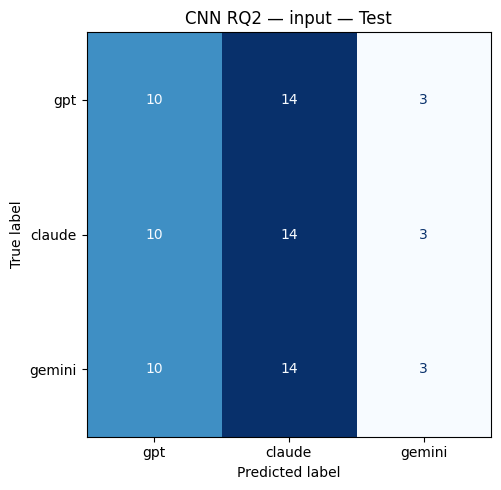


COMBINED — TEST RESULTS
Selected epoch: 7
Test accuracy: 77.78%
Test macro-F1: 0.7730
Correct: 63/81
              precision    recall  f1-score   support

         gpt     0.8889    0.5926    0.7111        27
      claude     0.8065    0.9259    0.8621        27
      gemini     0.6875    0.8148    0.7458        27

    accuracy                         0.7778        81
   macro avg     0.7943    0.7778    0.7730        81
weighted avg     0.7943    0.7778    0.7730        81



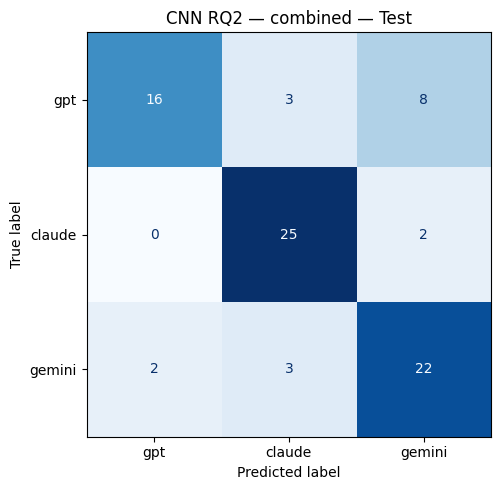


CNN comparison:
                             configuration  test_accuracy  test_macro_f1
                                Input-only       0.333333       0.307780
Output-only (RQ1, reported rounded values)       0.827200       0.829300
                                  Combined       0.777778       0.772981

All RQ2 files saved permanently to: /content/drive/MyDrive/CMPSC448/CNN_RQ2/20261011_175041_402732


In [17]:
# RQ2 — Final test evaluation and permanent export

from google.colab import drive
from pathlib import Path
import json
import shutil
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)

drive.mount("/content/drive")

rq2_export_dir = (
    Path("/content/drive/MyDrive/CMPSC448/CNN_RQ2")
    / rq2_run_dir.name
)
rq2_export_dir.mkdir(parents=True, exist_ok=True)

rq2_test_results = {}
rq2_names = [
    name for name, idx in sorted(
        LABEL_MAP.items(), key=lambda item: item[1]
    )
]
rq2_ids = list(range(len(LABEL_MAP)))

for mode in ["input", "combined"]:
    saved = torch.load(
        rq2_checkpoints[mode],
        map_location="cpu",
        weights_only=True,
    )

    assert saved["vocab"] == rq2_vocabs[mode]
    assert saved["label_map"] == LABEL_MAP

    eval_net = TextCNN(**saved["model_config"]).to(device)
    eval_net.load_state_dict(saved["model_state_dict"])
    eval_net.eval()

    actual, predicted = [], []

    with torch.inference_mode():
        for X, y in rq2_loaders[mode]["test"]:
            logits = eval_net(X.to(device))
            actual.extend(y.tolist())
            predicted.extend(logits.argmax(dim=1).cpu().tolist())

    matrix = confusion_matrix(actual, predicted, labels=rq2_ids)

    results = {
        "model": "CNN",
        "experiment": f"RQ2_{mode}",
        "selected_epoch": int(saved["epoch"]),
        "checkpoint_selection": saved["checkpoint_selection"],
        "validation_loss": float(saved["val_loss"]),
        "validation_accuracy": float(saved["val_accuracy"]),
        "validation_macro_f1": float(saved["val_macro_f1"]),
        "last_training_epoch": int(rq2_histories[mode][-1]["epoch"]),
        "test_accuracy": float(accuracy_score(actual, predicted)),
        "test_macro_f1": float(f1_score(
            actual, predicted, labels=rq2_ids,
            average="macro", zero_division=0,
        )),
        "test_samples": len(actual),
        "correct_predictions": sum(
            a == p for a, p in zip(actual, predicted)
        ),
        "label_map": dict(LABEL_MAP),
        "confusion_matrix_label_order": rq2_names,
        "confusion_matrix": matrix.tolist(),
        "encoding": saved["encoding"],
        "seed": saved["seed"],
        "classification_report": classification_report(
            actual, predicted, labels=rq2_ids,
            target_names=rq2_names,
            output_dict=True, zero_division=0,
        ),
    }
    rq2_test_results[mode] = results

    prefix = f"cnn_rq2_{mode}"

    with open(rq2_export_dir / f"{prefix}_metrics.json", "w") as f:
        json.dump(results, f, indent=2)

    with open(rq2_export_dir / f"{prefix}_vocab.json", "w") as f:
        json.dump(saved["vocab"], f, ensure_ascii=False, indent=2)

    pd.DataFrame(rq2_histories[mode]).to_csv(
        rq2_export_dir / f"{prefix}_history.csv", index=False
    )

    shutil.copy2(
        rq2_checkpoints[mode],
        rq2_export_dir / f"{prefix}_best.pt",
    )

    predictions = test_df[["prompt_id", "model"]].reset_index(
        drop=True
    ).copy()
    predictions["true_label_id"] = actual
    predictions["predicted_label_id"] = predicted
    predictions["predicted_model"] = [
        rq2_names[p] for p in predicted
    ]
    predictions.to_csv(
        rq2_export_dir / f"{prefix}_predictions.csv", index=False
    )

    print(f"\n{mode.upper()} — TEST RESULTS")
    print("Selected epoch:", results["selected_epoch"])
    print(f"Test accuracy: {results['test_accuracy']:.2%}")
    print(f"Test macro-F1: {results['test_macro_f1']:.4f}")
    print(
        f"Correct: {results['correct_predictions']}/"
        f"{results['test_samples']}"
    )
    print(classification_report(
        actual, predicted, labels=rq2_ids,
        target_names=rq2_names, digits=4, zero_division=0,
    ))

    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(
        matrix, display_labels=rq2_names
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"CNN RQ2 — {mode} — Test")
    fig.tight_layout()
    fig.savefig(
        rq2_export_dir / f"{prefix}_confusion_matrix.png", dpi=200
    )
    plt.show()
    plt.close(fig)

# Preserve the exact loaded data used for these experiments.
for split, frame in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    frame.to_csv(rq2_export_dir / f"{split}.csv", index=False)

comparison = pd.DataFrame([
    {
        "configuration": "Input-only",
        "test_accuracy": rq2_test_results["input"]["test_accuracy"],
        "test_macro_f1": rq2_test_results["input"]["test_macro_f1"],
    },
    {
        "configuration": "Output-only (RQ1, reported rounded values)",
        "test_accuracy": 0.8272,
        "test_macro_f1": 0.8293,
    },
    {
        "configuration": "Combined",
        "test_accuracy": rq2_test_results["combined"]["test_accuracy"],
        "test_macro_f1": rq2_test_results["combined"]["test_macro_f1"],
    },
])
comparison.to_csv(
    rq2_export_dir / "cnn_rq2_comparison.csv", index=False
)

print("\nCNN comparison:")
print(comparison.to_string(index=False))
print("\nAll RQ2 files saved permanently to:", rq2_export_dir)

## RQ2 Results and Interpretation

### Held-out Test Results

| Input configuration | CNN accuracy | CNN macro-F1 | LSTM accuracy | LSTM macro-F1 |
|---|---:|---:|---:|---:|
| Input-only | 33.33% | 0.3078 | 33.33% | 0.3281 |
| Output-only (RQ1) | **82.72%** | **0.8293** | **71.60%** | **0.7141** |
| Combined | 77.78% | 0.7730 | 53.09% | 0.5294 |

All configurations were evaluated on the held-out test split of 81 responses.

Output-only classification achieved the highest test accuracy and macro-F1 for both architectures. The CNN achieved 82.72% accuracy and 0.8293 macro-F1 using responses alone, compared with 77.78% accuracy and 0.7730 macro-F1 using combined prompts and responses. The LSTM achieved 71.60% accuracy and 0.7141 macro-F1 using responses alone, compared with 53.09% accuracy and 0.5294 macro-F1 using combined text.

Both input-only models achieved 33.33% accuracy, consistent with identical prompts appearing under all three model labels. Prompt text alone therefore provided no distinguishing signal in this dataset.

Including prompts did not improve attribution in these runs. However, the combined experiments also used a different vocabulary and retained at most 383 response tokens, compared with 512 for output-only. The CNN’s checkpoint-selection criterion also differed between RQ1 and RQ2: RQ1 used the lowest validation loss, while RQ2 used the highest validation macro-F1. Consequently, the performance differences cannot be attributed solely to adding prompt context.

In [18]:
# Prepare data for RQ3 and RQ4
analysis_df = pd.concat(
    [
        train_df.assign(original_split="train"),
        val_df.assign(original_split="validation"),
        test_df.assign(original_split="test"),
    ],
    ignore_index=True,
)

assert not analysis_df.duplicated(
    subset=["prompt_id", "model"]
).any()

print("Responses by category and model:")
print(pd.crosstab(analysis_df["category"], analysis_df["model"]))

print("\nUnique prompts per category:")
print(
    analysis_df.groupby("category")["prompt_id"]
    .nunique()
    .sort_index()
)

print("\nEach prompt belongs to one category:")
print(
    analysis_df.groupby("prompt_id")["category"]
    .nunique().eq(1).all()
)

Responses by category and model:
model            claude  gemini  gpt
category                            
cs_software          30      30   30
finance_banking      30      30   30
general_writing      30      30   30
math_logic           30      30   30
sports               30      30   30
stocks_trading       30      30   30

Unique prompts per category:
category
cs_software        30
finance_banking    30
general_writing    30
math_logic         30
sports             30
stocks_trading     30
Name: prompt_id, dtype: int64

Each prompt belongs to one category:
True


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Mean writing-style measurements:


,word_count,mean_word_length,type_token_ratio,mattr_50,punctuation_per_100_words
model,,,,,
claude,629.7111,4.9244,0.5055,0.8259,26.0010
gemini,328.7778,5.6832,0.6592,0.8625,41.2468
gpt,459.2722,5.7827,0.6309,0.8592,26.5300



Percentage of responses containing formatting markers:


,has_heading,has_list,has_code_fence,has_bold_marker
model,,,,
claude,0.56,61.67,0.00,19.44
gemini,39.44,33.33,23.89,46.67
gpt,30.56,19.44,5.00,25.56



Responses eligible for 50-word lexical-diversity measurement:
model
claude    180
gemini    180
gpt       179
Name: mattr_50, dtype: int64


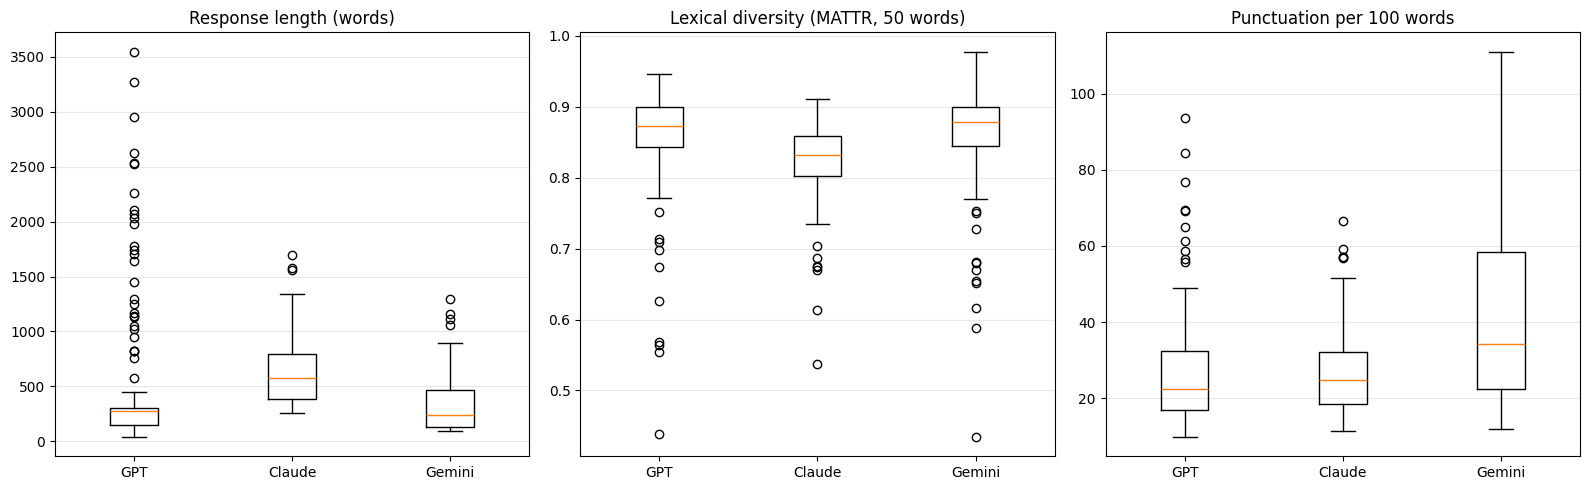

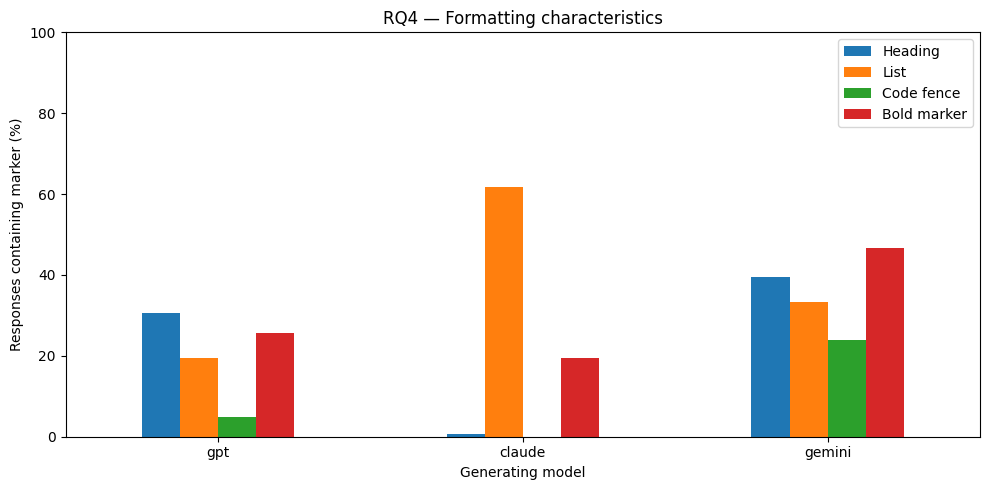


RQ4 files saved to: /content/drive/MyDrive/CMPSC448/RQ4/20261011_181534


In [21]:
# RQ4 — Descriptive writing-style analysis

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime
from google.colab import drive
from IPython.display import display

drive.mount("/content/drive")

rq4_dir = (
    Path("/content/drive/MyDrive/CMPSC448/RQ4")
    / datetime.now().strftime("%Y%m%d_%H%M%S")
)
rq4_dir.mkdir(parents=True, exist_ok=True)


def rq4_style_features(text):
    text = str(text)

    # Unicode word matches; lowercased only for diversity measurement.
    words = re.findall(r"\b\w+\b", text, flags=re.UNICODE)
    lower_words = [word.lower() for word in words]
    word_count = len(words)
    lines = text.splitlines()
    nonempty_lines = [line for line in lines if line.strip()]

    # Fixed 50-word windows reduce the length bias of ordinary TTR.
    if word_count >= 50:
        mattr = np.mean([
            len(set(lower_words[i:i + 50])) / 50
            for i in range(word_count - 49)
        ])
    else:
        mattr = np.nan

    heading_lines = sum(
        bool(re.match(r"^\s{0,3}#{1,6}\s+", line))
        for line in lines
    )
    list_lines = sum(
        bool(re.match(r"^\s*(?:[-*+]|\d+[.)])\s+", line))
        for line in lines
    )
    punctuation_count = len(re.findall(r"[^\w\s]", text))

    return {
        "word_count": word_count,
        "character_count": len(text),
        "mean_word_length": (
            np.mean([len(word) for word in words])
            if words else np.nan
        ),
        "type_token_ratio": (
            len(set(lower_words)) / word_count
            if word_count else np.nan
        ),
        "mattr_50": mattr,
        "nonempty_lines": len(nonempty_lines),
        "heading_lines": heading_lines,
        "list_lines": list_lines,
        "punctuation_per_100_words": (
            100 * punctuation_count / word_count
            if word_count else np.nan
        ),
        "has_heading": int(heading_lines > 0),
        "has_list": int(list_lines > 0),
        "has_code_fence": int("```" in text or "~~~" in text),
        "has_bold_marker": int("**" in text or "__" in text),
    }


rq4_features = analysis_df[
    ["prompt_id", "category", "model", "original_split"]
].reset_index(drop=True).copy()

feature_values = pd.DataFrame([
    rq4_style_features(text) for text in analysis_df["output"]
])
rq4_features = pd.concat([rq4_features, feature_values], axis=1)

feature_columns = feature_values.columns.tolist()

# Overall summaries
rq4_summary = rq4_features.groupby("model")[
    feature_columns
].agg(["mean", "median", "std", "count"])

# Category-specific summaries help check whether patterns vary by task.
rq4_by_category = rq4_features.groupby(
    ["category", "model"]
)[feature_columns].mean()

rq4_features.to_csv(rq4_dir / "rq4_response_features.csv", index=False)
rq4_summary.to_csv(rq4_dir / "rq4_summary_by_model.csv")
rq4_by_category.to_csv(rq4_dir / "rq4_summary_by_category_model.csv")

print("Mean writing-style measurements:")
display(
    rq4_features.groupby("model")[[
        "word_count",
        "mean_word_length",
        "type_token_ratio",
        "mattr_50",
        "punctuation_per_100_words",
    ]].mean().round(4)
)

print("\nPercentage of responses containing formatting markers:")
formatting_columns = [
    "has_heading", "has_list", "has_code_fence", "has_bold_marker"
]
display(
    (
        rq4_features.groupby("model")[formatting_columns].mean()
        * 100
    ).round(2)
)

print("\nResponses eligible for 50-word lexical-diversity measurement:")
print(rq4_features.groupby("model")["mattr_50"].count())

# Distribution plots
model_order = ["gpt", "claude", "gemini"]
plot_features = [
    ("word_count", "Response length (words)"),
    ("mattr_50", "Lexical diversity (MATTR, 50 words)"),
    ("punctuation_per_100_words", "Punctuation per 100 words"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (feature, title) in zip(axes, plot_features):
    groups = [
        rq4_features.loc[
            rq4_features["model"].eq(name), feature
        ].dropna().to_numpy()
        for name in model_order
    ]
    ax.boxplot(groups)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(["GPT", "Claude", "Gemini"])
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(rq4_dir / "rq4_style_distributions.png", dpi=200)
plt.show()
plt.close(fig)

# Formatting-frequency plot
formatting_rates = (
    rq4_features.groupby("model")[formatting_columns]
    .mean().reindex(model_order) * 100
)
formatting_rates.columns = [
    "Heading", "List", "Code fence", "Bold marker"
]
ax = formatting_rates.plot.bar(figsize=(10, 5))
ax.set_ylabel("Responses containing marker (%)")
ax.set_xlabel("Generating model")
ax.set_title("RQ4 — Formatting characteristics")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.figure.tight_layout()
ax.figure.savefig(rq4_dir / "rq4_formatting_rates.png", dpi=200)
plt.show()
plt.close(ax.figure)

print("\nRQ4 files saved to:", rq4_dir)

## RQ4: Writing-Style Results and Interpretation

We analyzed all 540 responses, with 180 responses per model and balanced representation across six task categories. This descriptive analysis was performed after the classification experiments and was not used to tune the classifiers.

| Measurement | GPT | Claude | Gemini |
|---|---:|---:|---:|
| Mean response length (words) | 459.27 | 629.71 | 328.78 |
| Mean lexical diversity (MATTR-50) | 0.8592 | 0.8259 | 0.8625 |
| Mean punctuation/symbol count per 100 words | 26.53 | 26.00 | 41.25 |
| Responses with heading markers (%) | 30.56 | 0.56 | 39.44 |
| Responses with list markers (%) | 19.44 | 61.67 | 33.33 |
| Responses with code fences (%) | 5.00 | 0.00 | 23.89 |
| Responses with bold markers (%) | 25.56 | 19.44 | 46.67 |

Claude produced the longest responses on average and used list markers most frequently. Gemini produced the shortest responses on average and used heading, code-fence, and bold markers most frequently. GPT showed intermediate average response length.

Lexical diversity was measured using the moving-average type-token ratio over 50-word windows (MATTR-50), reducing the length dependence of ordinary type-token ratio. Gemini and GPT had higher mean MATTR-50 than Claude, although their distributions overlapped. All Claude and Gemini responses qualified for this measurement; one GPT response shorter than 50 words was excluded.

These observations identify linguistic and structural differences within the collected dataset. They do not establish which features the CNN or LSTM actually used, nor whether the differences generalize to other prompts or model versions. Formatting detection uses simple marker rules, and the punctuation measure includes symbols such as Markdown and code characters. No statistical significance tests or feature-removal experiments were performed.

In [22]:
# RQ3 — Prepare cross-domain CNN experiment
# Training/validation: five source categories
# Unseen-domain test: general_writing

from sklearn.model_selection import train_test_split
from collections import Counter
from torch.utils.data import TensorDataset, DataLoader
import torch

RQ3_TARGET = "general_writing"

# Preserve the original source-domain train/validation/test partitions.
rq3_train_df = train_df[
    train_df["category"] != RQ3_TARGET
].copy()

rq3_val_df = val_df[
    val_df["category"] != RQ3_TARGET
].copy()

# Original source-domain test responses provide an in-domain comparison.
rq3_source_test_df = test_df[
    test_df["category"] != RQ3_TARGET
].copy()

# All target-domain responses are excluded from training and validation.
rq3_target_test_df = analysis_df[
    analysis_df["category"] == RQ3_TARGET
].copy()

rq3_frames = {
    "train": rq3_train_df,
    "validation": rq3_val_df,
    "source_test": rq3_source_test_df,
    "target_test": rq3_target_test_df,
}

# Verify prompt groups remain separate.
for name, frame in rq3_frames.items():
    assert len(frame) > 0
    assert set(frame["model"]) == set(LABEL_MAP)
    assert frame.groupby("prompt_id")["model"].nunique().eq(3).all()

names = list(rq3_frames)
for i, first in enumerate(names):
    for second in names[i + 1:]:
        assert set(rq3_frames[first]["prompt_id"]).isdisjoint(
            set(rq3_frames[second]["prompt_id"])
        )

# Build a NEW vocabulary using source-domain training outputs only.
rq3_counts = Counter(
    token
    for text in rq3_train_df["output"]
    for token in tokenize(text)
)

rq3_vocab = {"<PAD>": 0, "<UNK>": 1}
ranked_tokens = sorted(
    rq3_counts, key=lambda token: (-rq3_counts[token], token)
)

for token in ranked_tokens:
    if token not in rq3_vocab:
        rq3_vocab[token] = len(rq3_vocab)
    if len(rq3_vocab) >= MAX_VOCAB_SIZE:
        break


def rq3_encode(text):
    ids = [
        rq3_vocab.get(token, rq3_vocab["<UNK>"])
        for token in tokenize(text)
    ][:MAX_SEQUENCE_LENGTH]

    return ids + [rq3_vocab["<PAD>"]] * (
        MAX_SEQUENCE_LENGTH - len(ids)
    )


rq3_loaders = {}

for name, frame in rq3_frames.items():
    X = torch.tensor(
        [rq3_encode(text) for text in frame["output"]],
        dtype=torch.long,
    )
    y = torch.tensor(
        frame["model"].map(LABEL_MAP).tolist(),
        dtype=torch.long,
    )

    options = {
        "batch_size": BATCH_SIZE,
        "shuffle": name == "train",
    }
    if name == "train":
        options["generator"] = torch.Generator().manual_seed(SEED)

    rq3_loaders[name] = DataLoader(
        TensorDataset(X, y), **options
    )

    print(
        f"{name}: {len(frame)} responses, "
        f"{frame['prompt_id'].nunique()} prompts"
    )

print("\nUnseen test category:", RQ3_TARGET)
print("Training-only vocabulary size:", len(rq3_vocab))
print("Prompt separation checks passed.")

train: 315 responses, 105 prompts
validation: 69 responses, 23 prompts
source_test: 66 responses, 22 prompts
target_test: 90 responses, 30 prompts

Unseen test category: general_writing
Training-only vocabulary size: 10000
Prompt separation checks passed.


In [23]:
# RQ3 — Train CNN using source domains only

from pathlib import Path
from datetime import datetime
import random
import numpy as np
import pandas as pd
import torch

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

rq3_loaders["train"].generator.manual_seed(SEED)

rq3_run_dir = (
    Path("/content/cnn_rq3")
    / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
rq3_run_dir.mkdir(parents=True, exist_ok=False)

rq3_config = {
    "vocab_size": len(rq3_vocab),
    "embedding_dim": EMBEDDING_DIM,
    "num_classes": len(LABEL_MAP),
    "pad_idx": rq3_vocab["<PAD>"],
    "dropout": DROPOUT,
    "num_filters": 128,
    "kernel_sizes": (3, 5, 7),
}

rq3_model = TextCNN(**rq3_config).to(device)
rq3_loss_fn = torch.nn.CrossEntropyLoss()
rq3_optimizer = torch.optim.Adam(
    rq3_model.parameters(), lr=LEARNING_RATE
)

rq3_checkpoint_path = rq3_run_dir / "cnn_rq3_best.pt"
rq3_history = []
rq3_best_f1 = -1.0
rq3_waiting = 0

for epoch in range(1, MAX_EPOCHS + 1):
    train_scores = rq2_run_epoch(
        rq3_model,
        rq3_loaders["train"],
        rq3_loss_fn,
        rq3_optimizer,
    )
    val_scores = rq2_run_epoch(
        rq3_model,
        rq3_loaders["validation"],
        rq3_loss_fn,
    )

    rq3_history.append({
        "epoch": epoch,
        **{f"train_{k}": v for k, v in train_scores.items()},
        **{f"val_{k}": v for k, v in val_scores.items()},
    })

    improved = val_scores["macro_f1"] > rq3_best_f1

    if improved:
        rq3_best_f1 = val_scores["macro_f1"]
        rq3_waiting = 0

        torch.save({
            "model_state_dict": {
                name: tensor.detach().cpu().clone()
                for name, tensor in rq3_model.state_dict().items()
            },
            "model_config": rq3_config,
            "epoch": epoch,
            "val_loss": val_scores["loss"],
            "val_accuracy": val_scores["accuracy"],
            "val_macro_f1": val_scores["macro_f1"],
            "checkpoint_selection": "highest_source_validation_macro_f1",
            "vocab": dict(rq3_vocab),
            "label_map": dict(LABEL_MAP),
            "target_category": RQ3_TARGET,
            "source_categories": sorted(
                rq3_train_df["category"].unique().tolist()
            ),
            "max_sequence_length": MAX_SEQUENCE_LENGTH,
            "seed": SEED,
        }, rq3_checkpoint_path)
    else:
        rq3_waiting += 1

    print(
        f"Epoch {epoch:02d} | "
        f"Train loss {train_scores['loss']:.4f} | "
        f"Val loss {val_scores['loss']:.4f} | "
        f"Val accuracy {val_scores['accuracy']:.2%} | "
        f"Val macro-F1 {val_scores['macro_f1']:.4f}"
        + (" | Saved best" if improved else "")
    )

    if rq3_waiting >= PATIENCE:
        print("Early stopping.")
        break

rq3_selected = torch.load(
    rq3_checkpoint_path,
    map_location="cpu",
    weights_only=True,
)
rq3_model.load_state_dict(rq3_selected["model_state_dict"])
rq3_model.eval()

pd.DataFrame(rq3_history).to_csv(
    rq3_run_dir / "cnn_rq3_history.csv", index=False
)

print("\nSelected epoch:", rq3_selected["epoch"])
print(
    "Source validation macro-F1:",
    f"{rq3_selected['val_macro_f1']:.4f}",
)
print("Temporary checkpoint:", rq3_checkpoint_path)

Epoch 01 | Train loss 1.1682 | Val loss 0.9468 | Val accuracy 55.07% | Val macro-F1 0.4582 | Saved best
Epoch 02 | Train loss 0.5575 | Val loss 0.7219 | Val accuracy 63.77% | Val macro-F1 0.5636 | Saved best
Epoch 03 | Train loss 0.2944 | Val loss 0.5440 | Val accuracy 89.86% | Val macro-F1 0.8960 | Saved best
Epoch 04 | Train loss 0.1776 | Val loss 0.4896 | Val accuracy 92.75% | Val macro-F1 0.9263 | Saved best
Epoch 05 | Train loss 0.1269 | Val loss 0.4369 | Val accuracy 89.86% | Val macro-F1 0.8979
Epoch 06 | Train loss 0.0834 | Val loss 0.4141 | Val accuracy 94.20% | Val macro-F1 0.9405 | Saved best
Epoch 07 | Train loss 0.0575 | Val loss 0.3898 | Val accuracy 91.30% | Val macro-F1 0.9120
Epoch 08 | Train loss 0.0514 | Val loss 0.3830 | Val accuracy 86.96% | Val macro-F1 0.8690
Epoch 09 | Train loss 0.0359 | Val loss 0.3803 | Val accuracy 88.41% | Val macro-F1 0.8842
Epoch 10 | Train loss 0.0337 | Val loss 0.3888 | Val accuracy 86.96% | Val macro-F1 0.8700
Early stopping.

Selected

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

SOURCE_TEST
Accuracy: 89.39%
Macro-F1: 0.8932
Correct: 59/66
              precision    recall  f1-score   support

         gpt     0.9091    0.9091    0.9091        22
      claude     0.9130    0.9545    0.9333        22
      gemini     0.8571    0.8182    0.8372        22

    accuracy                         0.8939        66
   macro avg     0.8931    0.8939    0.8932        66
weighted avg     0.8931    0.8939    0.8932        66



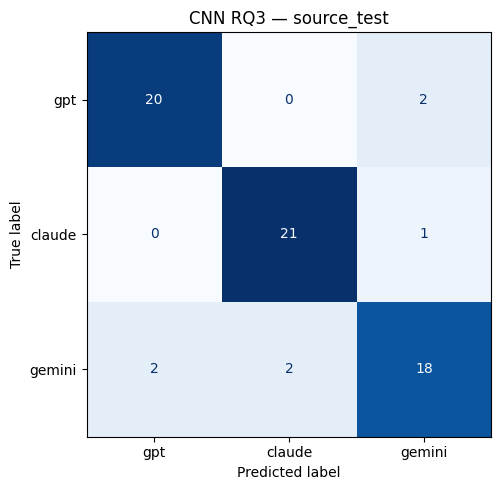


TARGET_TEST
Accuracy: 72.22%
Macro-F1: 0.7161
Correct: 65/90
              precision    recall  f1-score   support

         gpt     0.5870    0.9000    0.7105        30
      claude     0.8235    0.4667    0.5957        30
      gemini     0.8889    0.8000    0.8421        30

    accuracy                         0.7222        90
   macro avg     0.7665    0.7222    0.7161        90
weighted avg     0.7665    0.7222    0.7161        90



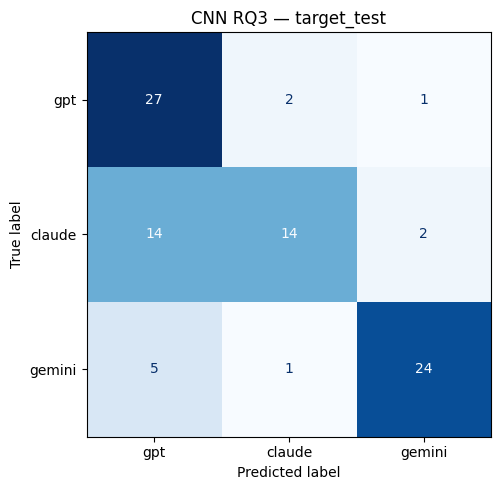


RQ3 comparison:
 test_split  responses  accuracy  macro_f1
source_test         66  0.893939  0.893211
target_test         90  0.722222  0.716125

RQ3 files saved permanently to: /content/drive/MyDrive/CMPSC448/RQ3/20261011_182239_397583


In [24]:
# RQ3 — Source-domain and unseen-domain test evaluation

from google.colab import drive
from pathlib import Path
import json
import shutil
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)

drive.mount("/content/drive")

rq3_export_dir = (
    Path("/content/drive/MyDrive/CMPSC448/RQ3")
    / rq3_run_dir.name
)
rq3_export_dir.mkdir(parents=True, exist_ok=True)

saved_rq3 = torch.load(
    rq3_checkpoint_path, map_location="cpu", weights_only=True
)
assert saved_rq3["vocab"] == rq3_vocab
assert saved_rq3["label_map"] == LABEL_MAP

rq3_eval_model = TextCNN(**saved_rq3["model_config"]).to(device)
rq3_eval_model.load_state_dict(saved_rq3["model_state_dict"])
rq3_eval_model.eval()

rq3_ids = list(range(len(LABEL_MAP)))
rq3_names = [
    name for name, idx in sorted(
        LABEL_MAP.items(), key=lambda item: item[1]
    )
]
rq3_results = {}

for split in ["source_test", "target_test"]:
    actual, predicted = [], []

    with torch.inference_mode():
        for X, y in rq3_loaders[split]:
            logits = rq3_eval_model(X.to(device))
            actual.extend(y.tolist())
            predicted.extend(logits.argmax(dim=1).cpu().tolist())

    matrix = confusion_matrix(actual, predicted, labels=rq3_ids)
    report = classification_report(
        actual, predicted, labels=rq3_ids,
        target_names=rq3_names,
        output_dict=True, zero_division=0,
    )

    result = {
        "model": "CNN",
        "experiment": "RQ3_output_only_cross_domain",
        "evaluation_split": split,
        "target_category": RQ3_TARGET,
        "source_categories": saved_rq3["source_categories"],
        "selected_epoch": int(saved_rq3["epoch"]),
        "checkpoint_selection": saved_rq3["checkpoint_selection"],
        "source_validation_accuracy": float(saved_rq3["val_accuracy"]),
        "source_validation_macro_f1": float(saved_rq3["val_macro_f1"]),
        "test_accuracy": float(accuracy_score(actual, predicted)),
        "test_macro_f1": float(f1_score(
            actual, predicted, labels=rq3_ids,
            average="macro", zero_division=0,
        )),
        "test_samples": len(actual),
        "correct_predictions": sum(
            a == p for a, p in zip(actual, predicted)
        ),
        "class_order": rq3_names,
        "confusion_matrix": matrix.tolist(),
        "classification_report": report,
        "seed": SEED,
        "max_sequence_length": MAX_SEQUENCE_LENGTH,
    }
    rq3_results[split] = result

    with open(
        rq3_export_dir / f"cnn_rq3_{split}_metrics.json", "w"
    ) as f:
        json.dump(result, f, indent=2)

    predictions = rq3_frames[split][
        ["prompt_id", "category", "model"]
    ].reset_index(drop=True).copy()
    predictions["true_label_id"] = actual
    predictions["predicted_label_id"] = predicted
    predictions["predicted_model"] = [
        rq3_names[p] for p in predicted
    ]
    predictions.to_csv(
        rq3_export_dir / f"cnn_rq3_{split}_predictions.csv",
        index=False,
    )

    print(f"\n{split.upper()}")
    print(f"Accuracy: {result['test_accuracy']:.2%}")
    print(f"Macro-F1: {result['test_macro_f1']:.4f}")
    print(
        f"Correct: {result['correct_predictions']}/"
        f"{result['test_samples']}"
    )
    print(classification_report(
        actual, predicted, labels=rq3_ids,
        target_names=rq3_names, digits=4, zero_division=0,
    ))

    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(
        matrix, display_labels=rq3_names
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"CNN RQ3 — {split}")
    fig.tight_layout()
    fig.savefig(
        rq3_export_dir / f"cnn_rq3_{split}_confusion_matrix.png",
        dpi=200,
    )
    plt.show()
    plt.close(fig)

# Preserve checkpoint, history, vocabulary, and experiment partitions.
shutil.copy2(
    rq3_checkpoint_path, rq3_export_dir / "cnn_rq3_best.pt"
)
pd.DataFrame(rq3_history).to_csv(
    rq3_export_dir / "cnn_rq3_history.csv", index=False
)
with open(rq3_export_dir / "cnn_rq3_vocab.json", "w") as f:
    json.dump(rq3_vocab, f, ensure_ascii=False, indent=2)

for split, frame in rq3_frames.items():
    frame.to_csv(rq3_export_dir / f"{split}.csv", index=False)

rq3_comparison = pd.DataFrame([
    {
        "test_split": split,
        "responses": result["test_samples"],
        "accuracy": result["test_accuracy"],
        "macro_f1": result["test_macro_f1"],
    }
    for split, result in rq3_results.items()
])
rq3_comparison.to_csv(
    rq3_export_dir / "cnn_rq3_comparison.csv", index=False
)

print("\nRQ3 comparison:")
print(rq3_comparison.to_string(index=False))
print("\nRQ3 files saved permanently to:", rq3_export_dir)

## RQ3: Cross-Domain Generalization — CNN

We trained a fresh output-only CNN on five categories: cs_software, finance_banking, math_logic, sports, and stocks_trading. All general_writing responses were excluded from training and validation.

The experiment used 315 training responses and 69 source-domain validation responses. A new vocabulary was built using only the training outputs. Prompt groups remained separate across partitions. The checkpoint was selected at epoch 6 using the highest source-domain validation macro-F1.

### Test Results

| Evaluation set | Responses | Accuracy | Macro-F1 | Correct |
|---|---:|---:|---:|---:|
| Source-domain test | 66 | 89.39% | 0.8932 | 59/66 |
| Unseen general_writing test | 90 | 72.22% | 0.7161 | 65/90 |

Accuracy decreased by approximately 17.17 percentage points on the unseen writing category, while macro-F1 decreased by approximately 0.1771. The model retained performance above the balanced three-class chance baseline of 33.33%, suggesting partial transfer across domains.

On the unseen writing responses, recall was 90.00% for GPT, 46.67% for Claude, and 80.00% for Gemini. Fourteen Claude responses were incorrectly classified as GPT, making this the largest confusion.

These results suggest that some attribution signals transfer across domains, while performance also depends on the task. However, this experiment covers only one held-out category, one CNN training run, and relatively small test sets. It does not establish generalization across all domains or prove whether the classifier uses general stylistic fingerprints or task-specific patterns. This section presents the CNN results for RQ3; the corresponding LSTM results are reported separately in the LSTM notebook.